# Variational reconstruction (TV + NUFFT)

This notebook demonstrates vendor-agnostic reconstruction utilities in `mrax.reco`.

The variational objective solved is:

$$\min_x \; \tfrac{1}{2}\| M\,F\,(S\,x) - y\|_2^2 + \lambda\,\mathrm{TV}(x)$$

- `S`: coil sensitivity maps (optional)
- `F`: centered FFT (Cartesian) or NUFFT (non-Cartesian)
- `M`: sampling mask (Cartesian)

Solves use the project's Optax/proximal tooling (e.g., FISTA + a TV proximal operator).

**Dimension note:** MRax keeps non-spatial axes explicit (e.g., `t`, `te`, `ti`, `offset`, `b1`) and reserves `x/y/z` for spatial.
When data arrives with a single frame axis, importers reshape it to these dimensions and observables are expanded across them during fitting.


In [1]:
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from pathlib import Path
from mrax.reco import build_operator, fftnc, reconstruct_ifft, reconstruct_regrid, reconstruct_variational

mse = lambda a, b: float(np.mean((np.abs(np.asarray(a) - np.asarray(b))) ** 2))


## Cartesian: zero-filled vs TV-regularized

Create an undersampled Cartesian acquisition (keep a small ACS region + every 8th ky line),
then compare a zero-filled reconstruction against a TV-regularized variational solve.

Note: `regularizer_weight` is scale-dependent; for orthonormal FFT k-space this demo uses a
small value (around `1e-4`).

Sampling fraction: 0.333
MSE zero-filled: 0.01914
MSE TV recon:    0.00813


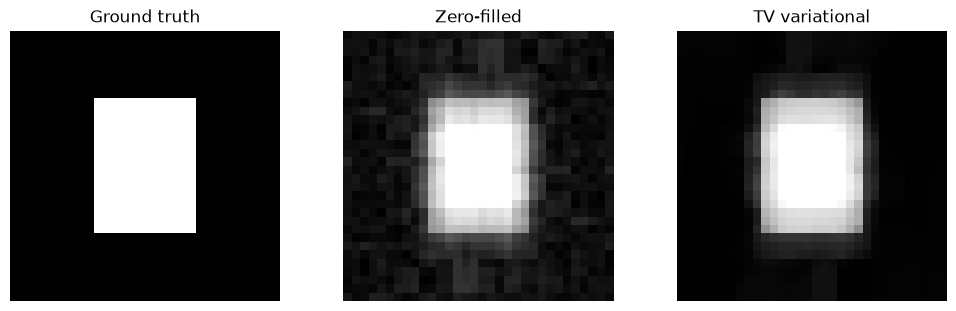

In [2]:
n = 32
phantom = jnp.zeros((n, n), dtype=jnp.float32).at[8:24, 10:22].set(1.0)
k_full = fftnc(phantom)

# Pseudo-random undersampling mask with fully sampled center
mask = np.zeros((n, n), dtype=bool)
mask[2*n//5:3*n//5, 2*n//5:3*n//5] = True  # fully sampled center
num_samples = n * n // 3  # target number of samples
rng = np.random.default_rng(0)
while mask.sum() < num_samples:
    x = rng.integers(0, n)
    y = rng.integers(0, n)
    mask[x, y] = True

k_us = np.asarray(k_full) * mask

zf = np.asarray(reconstruct_ifft(k_us, mask=mask))
tv = np.asarray(
    reconstruct_variational(
        k_us,
        mask=mask,
        optimizer_name="fista",
        step_size=1.0,
        num_steps=120,
        regularizer="tv",
        regularizer_weight=1e-4,
        tv_iterations=60,
    )
)

print(f"Sampling fraction: {mask.mean():.3f}")
print(f"MSE zero-filled: {mse(phantom, zf):.4g}")
print(f"MSE TV recon:    {mse(phantom, tv):.4g}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
axs[0].imshow(np.asarray(phantom), cmap="gray", vmin=0, vmax=1)
axs[0].set_title("Ground truth")
axs[1].imshow(np.abs(zf), cmap="gray", vmin=0, vmax=1)
axs[1].set_title("Zero-filled")
axs[2].imshow(np.abs(tv), cmap="gray", vmin=0, vmax=1)
axs[2].set_title("TV variational")
for ax in axs:
    ax.axis("off")
plt.show()

## Cartesian multi-coil SENSE-style example

Simulate two smooth coil sensitivity maps and reconstruct the combined image using the
explicit coil patterns in the forward model.

Tip: normalizing sensitivities so that `sum(|S|^2)=1` improves conditioning in this toy setup.

MSE SENSE adjoint: 0.01652
MSE SENSE + TV:    0.01418


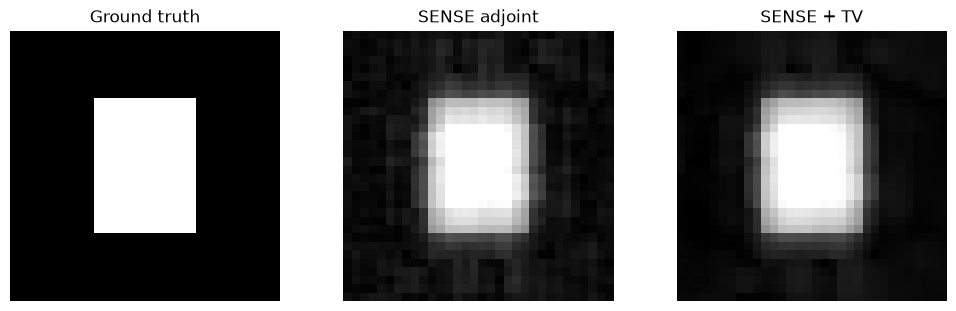

In [3]:
yy, xx = np.meshgrid(np.linspace(-1, 1, n), np.linspace(-1, 1, n), indexing="ij")
sens1 = np.exp(-2.0 * (xx**2 + yy**2))
sens2 = np.exp(-2.0 * ((xx - 0.4) ** 2 + yy**2)) * np.exp(1j * (np.pi * xx))
sens = np.stack([sens1, sens2], axis=0).astype(np.complex64)

# SOS-normalize: sum(|S|^2)=1.
sens = sens / np.sqrt(np.sum(np.abs(sens) ** 2, axis=0, keepdims=True) + 1e-8)

coil_imgs = np.asarray(phantom)[None, :, :] * sens
k_coils = np.asarray(fftnc(jnp.asarray(coil_imgs)))
k_coils_us = k_coils * mask  # broadcast mask over coils

zf_sense = np.asarray(reconstruct_ifft(k_coils_us, sensitivities=sens, mask=mask))
recon_sense = np.asarray(
    reconstruct_variational(
        k_coils_us,
        sensitivities=sens,
        mask=mask,
        optimizer_name="fista",
        step_size=0.01,
        num_steps=500,
        regularizer="tv",
        regularizer_weight=1e-4,
        tv_iterations=30,
    )
)

print(f"MSE SENSE adjoint: {mse(phantom, zf_sense):.4g}")
print(f"MSE SENSE + TV:    {mse(phantom, recon_sense):.4g}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
axs[0].imshow(np.asarray(phantom), cmap="gray", vmin=0, vmax=1)
axs[0].set_title("Ground truth")
axs[1].imshow(np.abs(zf_sense), cmap="gray", vmin=0, vmax=1)
axs[1].set_title("SENSE adjoint")
axs[2].imshow(np.abs(recon_sense), cmap="gray", vmin=0, vmax=1)
axs[2].set_title("SENSE + TV")
for ax in axs:
    ax.axis("off")
plt.show()

## Non-Cartesian example (NUFFT + regridding)

When you supply a non-Cartesian trajectory (in cycles/pixel), the operator uses FINUFFT (`jax-finufft`) for forward/adjoint operations.

- `reconstruct_regrid`: nearest-neighbor regridding + IFFT preview
- `reconstruct_variational`: iterative solve with the NUFFT forward model

Trajectory convention: `trajectory[:, 0] = kx`, `trajectory[:, 1] = ky`.

MSE regridding: 0.07012
MSE NUFFT iter: 0.02874


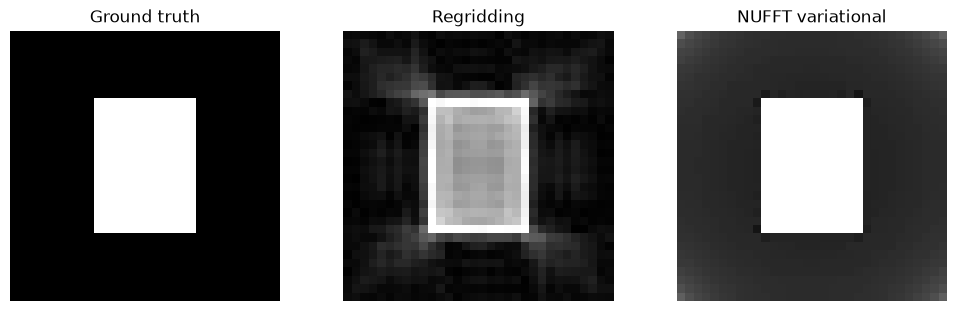

In [4]:
num_spokes = 64
num_samples = n

r = np.linspace(-0.5, 0.5, num_samples, endpoint=False, dtype=np.float32)
angles = np.linspace(0, np.pi, num_spokes, endpoint=False, dtype=np.float32)
kx = (r[None, :] * np.cos(angles)[:, None]).reshape(-1)
ky = (r[None, :] * np.sin(angles)[:, None]).reshape(-1)
traj = np.stack([kx, ky], axis=1).astype(np.float32)

# Density compensation is applied by default for non-Cartesian trajectories (simple |k| DCF
# normalized so weights sum to the number of spatial pixels). Pass
# density=np.ones(traj.shape[0]) to disable or provide custom weights.
density = None

op = build_operator(spatial_shape=(n, n), trajectory=traj, density=density)
samples = np.asarray(op.forward(phantom))[0]
scale = np.max(np.abs(samples)) + 1e-8
samples = samples / scale

regrid_img = np.asarray(reconstruct_regrid(samples, traj, spatial_shape=(n, n), density=density))

schedule = [(1e-3, 120)]
tv_lambda = 5e-3
x0 = None
for step_size, steps in schedule:
    x0, stage_history = reconstruct_variational(
        samples,
        spatial_shape=(n, n),
        trajectory=traj,
        density=density,
        optimizer_name="split_bregman",
        step_size=step_size,
        num_steps=steps,
        regularizer="tv",
        regularizer_weight=tv_lambda / step_size,
        initial_image=x0,
        return_history=True,
    )
    if not np.isfinite(np.asarray(stage_history)).all():
        raise RuntimeError("Non-finite loss; lower step_size or clip gradients more.")
    if not np.isfinite(np.asarray(x0)).all():
        raise RuntimeError("Non-finite image; lower step_size or clip gradients more.")
iter_img = np.asarray(x0)

regrid_img = regrid_img * scale
iter_img = iter_img * scale

print(f"MSE regridding: {mse(phantom, regrid_img):.4g}")
print(f"MSE NUFFT iter: {mse(phantom, iter_img):.4g}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
axs[0].imshow(np.asarray(phantom), cmap="gray", vmin=0, vmax=1)
axs[0].set_title("Ground truth")
axs[1].imshow(np.abs(regrid_img), cmap="gray", vmin=0, vmax=1)
axs[1].set_title("Regridding")
axs[2].imshow(np.abs(iter_img), cmap="gray", vmin=0, vmax=1)
axs[2].set_title("NUFFT variational")
for ax in axs:
    ax.axis("off")
plt.show()
